In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

In [3]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
cat_cols = df.select_dtypes(include=['object']).columns
num_cols = df.select_dtypes(include=['number']).columns
df[cat_cols] = df[cat_cols].fillna('NA')
df[num_cols] = df[num_cols].fillna(0.0)


/var/folders/yy/t95v8nfd5mg826zr_b6pmwf00000gp/T/ipykernel_2541/3162506074.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


In [6]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [7]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [8]:
y_train, y_val, y_test = df_train['converted'], df_val['converted'], df_test['converted']

In [9]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [10]:
from sklearn.metrics import roc_auc_score, roc_curve, auc

In [11]:

num_cols = df_train.select_dtypes(include=['number']).columns

print(num_cols)

Index(['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score'],
      dtype='str')


In [12]:
scores = {}
for col in num_cols:
    scores[col] = roc_auc_score(y_train, df_train[col])

In [13]:
for col, score in scores.items():
    if score < 0.5:
        scores[col] = roc_auc_score(y_train, -df_train[col])
print(scores)

{'annual_income': 0.6081977776250831, 'number_of_courses_viewed': 0.7229894623989618, 'interaction_count': 0.7649203047563227, 'lead_score': 0.7882254810906102}


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [15]:
preprocessor = ColumnTransformer(
    transformers =  [
        ("cat", OneHotEncoder(drop="first",sparse_output=False, handle_unknown="ignore"), cat_cols)
    ], remainder="passthrough"
)
preprocessor.set_output(transform="pandas")

df_train = preprocessor.fit_transform(df_train) 
df_val = preprocessor.transform(df_val) 
df_test = preprocessor.transform(df_test) 

In [16]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(df_train, y_train)
y_pred = model.predict_proba(df_val)[:,1]

round(roc_auc_score(y_val, y_pred), 3)

0.732

In [17]:
from sklearn.metrics import recall_score, precision_score

In [18]:
thresholds = np.linspace(0, 1, 101)
scores = []
for t in thresholds:
    prec = precision_score(y_val, y_pred>t, zero_division=0)
    rec = recall_score(y_val, y_pred>t)
    scores.append([t, prec, rec])

print(scores)



[[np.float64(0.0), 0.586, 1.0], [np.float64(0.01), 0.586, 1.0], [np.float64(0.02), 0.586, 1.0], [np.float64(0.03), 0.586, 1.0], [np.float64(0.04), 0.586, 1.0], [np.float64(0.05), 0.586, 1.0], [np.float64(0.06), 0.586, 1.0], [np.float64(0.07), 0.586, 1.0], [np.float64(0.08), 0.586, 1.0], [np.float64(0.09), 0.586, 1.0], [np.float64(0.1), 0.586, 1.0], [np.float64(0.11), 0.586, 1.0], [np.float64(0.12), 0.586, 1.0], [np.float64(0.13), 0.586, 1.0], [np.float64(0.14), 0.586, 1.0], [np.float64(0.15), 0.586, 1.0], [np.float64(0.16), 0.586, 1.0], [np.float64(0.17), 0.586, 1.0], [np.float64(0.18), 0.586, 1.0], [np.float64(0.19), 0.586, 1.0], [np.float64(0.2), 0.586, 1.0], [np.float64(0.21), 0.586, 1.0], [np.float64(0.22), 0.586, 1.0], [np.float64(0.23), 0.586, 1.0], [np.float64(0.24), 0.586, 1.0], [np.float64(0.25), 0.586, 1.0], [np.float64(0.26), 0.5865865865865866, 1.0], [np.float64(0.27), 0.5877632898696088, 1.0], [np.float64(0.28), 0.591321897073663, 1.0], [np.float64(0.29), 0.591321897073663

In [19]:
cols = ["t", "precision", "recall"]
prec_rec = pd.DataFrame(scores,columns=cols)

In [20]:
import matplotlib.pyplot as plt

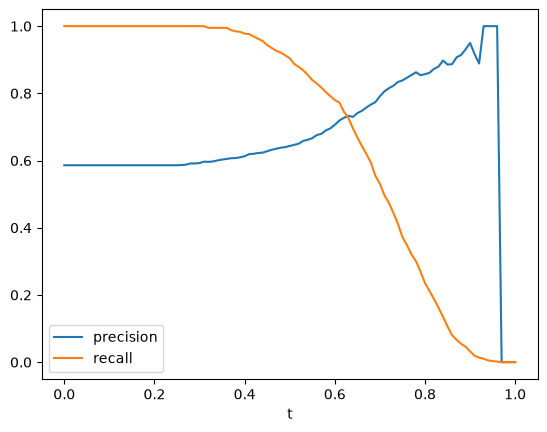

In [21]:
prec_rec.plot(x="t", y=["precision", "recall"])
plt.show()

Best threshold: 0.41000000000000003
Maximum F1: 0.7576158940397352


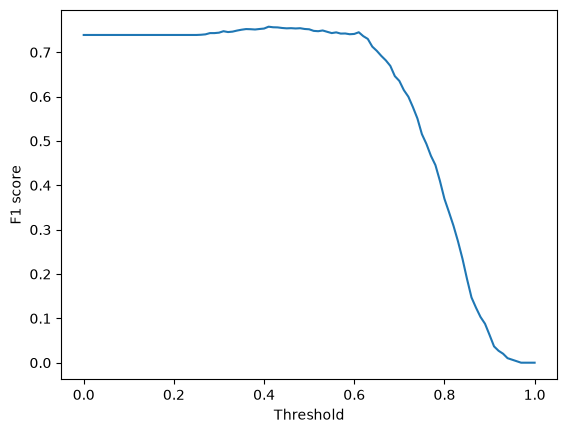

In [26]:
thresholds = np.linspace(0, 1, 101)
f1_scores = []
for t in thresholds:
    prec = precision_score(y_val, y_pred>t, zero_division=0)
    rec = recall_score(y_val, y_pred>t)
    if prec + rec > 0:
        f1 = 2 * ((prec * rec) / (prec + rec))
    else:
        f1 = 0
    f1_scores.append((t,f1))

best_threshold, best_f1 = max(f1_scores, key = lambda x: x[1])

print("Best threshold:", best_threshold)
print("Maximum F1:", best_f1)

plt.plot(thresholds, [score for _, score in f1_scores])
plt.xlabel("Threshold")
plt.ylabel("F1 score")
plt.show()

In [32]:
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer


In [33]:
kf = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kf.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    X_train = df_train.drop(columns=['converted'])
    X_val = df_val.drop(columns=['converted'])


    train_dict = X_train.to_dict(orient='records')
    val_dict = X_val.to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_dict)
    X_val = dv.transform(val_dict)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)
    y_pred = model.predict_proba(X_val)[:,1]

    auc = round(roc_auc_score(y_val, y_pred), 3)
    scores.append(auc)
print(' %.3f +- %.3f' % (np.mean(scores), np.std(scores)))

 0.732 +- 0.007


In [34]:
from tqdm.auto import tqdm

/Users/apple/Library/Python/3.11/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [36]:
for C in tqdm([0.000001, 0.001, 1]):
    kf = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kf.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        X_train = df_train.drop(columns=['converted'])
        X_val = df_val.drop(columns=['converted'])


        train_dict = X_train.to_dict(orient='records')
        val_dict = X_val.to_dict(orient='records')

        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(train_dict)
        X_val = dv.transform(val_dict)

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train, y_train)
        y_pred = model.predict_proba(X_val)[:,1]

        auc = round(roc_auc_score(y_val, y_pred), 3)
        scores.append(auc)
    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

 67%|██████▋   | 2/3 [00:00<00:00,  7.59it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010


100%|██████████| 3/3 [00:00<00:00,  7.50it/s]

C=1 0.732 +- 0.007
